# M3 T2 Practical — Activation and Loss Functions

Revision: 15 September 2026

## Learning outcomes

- Interpret activation outputs, gradients and saturation.
- Compare BCE confidence penalties and MSE/MAE sensitivity to large regression errors.
- Trace a forward pass and predict the effect of a bias intervention.
- Compare activations on validation evidence before a final test evaluation.
- Diagnose inappropriate output/loss pairings for different target types.
- Implement and validate the modelling or evaluation code required in this activity.


## How to work and submit

Plan for a two-hour session: about 90 minutes of core work and 30 minutes for discussion, debugging and checking. Timings beside questions are estimates, not deadlines. Setup and plotting support are supplied; focus on the modelling ideas.

Run cells in order. Replace `...` in TODO cells and write in each answer cell. Make a prediction **before** running an experiment; keep it even if the result surprises you, then explain the difference. If a cell fails, ask about the first error and retain your genuine attempt.

For every explanation, cite a number, observation or intermediate value from your own run, explain what it means, and justify your conclusion. Concise supported answers are enough. Different justified choices may be valid. Save your notebook with outputs and written answers. Supplied code alone is not a completed response.

The five core questions are assessed using the course's 50% completion/genuine attempt and 50% demonstrated understanding criteria. Optional extensions are not required. No new package installation or external dataset download is needed in the course Python environment (NumPy, pandas, matplotlib and scikit-learn).

## Preparation and links to the topic

Review [M3 T2 overview](https://learn.adelaide.edu.au/courses/30362/pages/module-3-topic-2-overview), [Activation function](https://learn.adelaide.edu.au/courses/30362/pages/activation-function) and [Loss function](https://learn.adelaide.edu.au/courses/30362/pages/loss-function). Q1–3 connect local activation calculations to predictions and losses; Q4 implements the taught validation/refit workflow; Q5 checks task/output/loss compatibility.

Observations are rows. For X with shape (n,d) and m hidden units, the hidden weight array has shape (d,m) (it stores W₁ᵀ from the Canvas notation), so X@W+b has shape (n,m). `@` is matrix multiplication; `*` is element-wise multiplication. L-BFGS is supplied to reduce incidental coding: explaining its internal algorithm is not required. During model selection fit preprocessing on training data only, then use validation for choices and test only for the final fixed model.

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

# Activation functions are implemented in Question 1.


## Question 1 — Implement activation values and gradients (15 minutes)

Implement the six functions below using the supplied formulas. Use vectorised NumPy operations, run the checks, then inspect the supplied table and plots. Briefly compare ranges and saturation, explain the ReLU derivative convention at zero, and state why stacking affine layers without nonlinearities would limit the network.

,z,sigmoid,sigmoid_grad,tanh,tanh_grad,ReLU,ReLU_grad
0,-5.0,0.0067,0.0066,-0.9999,0.0002,0.0,0.0
1,-2.0,0.1192,0.1050,-0.9640,0.0707,0.0,0.0
2,0.0,0.5000,0.2500,0.0000,1.0000,0.0,0.0
3,2.0,0.8808,0.1050,0.9640,0.0707,2.0,1.0
4,5.0,0.9933,0.0066,0.9999,0.0002,5.0,1.0


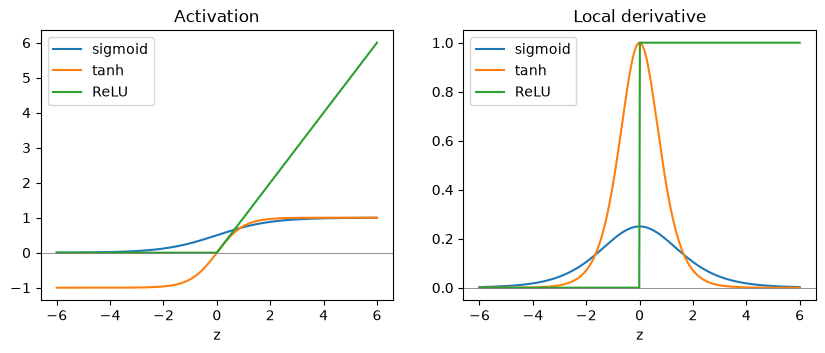

In [9]:
# TODO: implement full NumPy expressions; all functions preserve input shape.
# sigmoid(z)=1/(1+exp(-z)); tanh(z)=np.tanh(z); ReLU(z)=max(0,z).
# Derivatives: sigmoid*(1-sigmoid), 1-tanh^2, and 1 where z>0.
def sigmoid(z):
    return 1/(1+np.exp(-z))
def tanh(z):
    return np.tanh(z)
def relu(z):
    return np.maximum(0,z)
def sigmoid_grad(z):
    s=sigmoid(z)
    return s*(1-s)
def tanh_grad(z):
    return 1-np.tanh(z)**2
def relu_grad(z):
    return (np.asarray(z)>0).astype(float) # Using astype(float) returns the array of the same shape, as the TODO requires.

# Simple boundary and shape checks; not a substitute for explaining the curves.
assert np.allclose(relu(np.array([-2., 0., 3.])), [0., 0., 3.])
assert np.allclose(relu_grad(np.array([-2., 0., 3.])), [0., 0., 1.])
assert np.isclose(sigmoid(np.array([0.]))[0], 0.5)
z_values = np.array([-5., -2., 0., 2., 5.])
activation_table = pd.DataFrame({
    "z": z_values,
    "sigmoid": sigmoid(z_values), "sigmoid_grad": sigmoid_grad(z_values),
    "tanh": tanh(z_values), "tanh_grad": tanh_grad(z_values),
    "ReLU": relu(z_values), "ReLU_grad": relu_grad(z_values),
})
display(activation_table.round(4))

z = np.linspace(-6, 6, 500)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for name, f in [("sigmoid", sigmoid), ("tanh", tanh), ("ReLU", relu)]:
    ax[0].plot(z, f(z), label=name)
for name, f in [("sigmoid", sigmoid_grad), ("tanh", tanh_grad), ("ReLU", relu_grad)]:
    ax[1].plot(z, f(z), label=name)
ax[0].set_title("Activation"); ax[1].set_title("Local derivative")
for a in ax:
    a.axhline(0, color="grey", linewidth=0.6); a.legend(); a.set_xlabel("z")
plt.show()

### Write your answer — Question 1

Sigmoid is bounded in (0,1), tanh in (-1,1), and ReLU in (0, ∞). ReLU has the widest range because it's unbounded above, and sigmoid has the narrowest. At z = ±5, the sigmoid_grad is 0.0066 and tanh_grad is 0.0002, so their gradients saturates for large z. ReLU's gradient stays at 1 for every positive z, so it doesn't saturate there. For negative z it's exactly 0.

At z = 0, ReLU has a sharp corner, its slope is 0 from the left (because the function is flat) and 1 from the right (because the function rises linearly). Since these slopes disagree, the derivative doesn't exist at z = 0, or it is undefined. However, since neural networks requires a derivative value, a common convention is chosen, usually 0 (which is what we're using).

Stacking affine layers without nonlinearities collapses into a single affine transformation, since the composition of affine maps is affine. The network could only represent linear relationships, no matter how many layer it has.

## Question 2 — Which errors does a loss emphasise? (15 minutes)

Implement binary_cross_entropy to return per-observation losses. Identify a confident wrong probability and explain clipping. Before running the extra comparisons, predict whether A and B can have the same accuracy but different BCE, and whether the large regression error affects MSE or MAE more strongly. Report the comparisons and explain the mechanisms. Do not compare absolute loss magnitudes across different units/tasks as if they shared one scale.

In [10]:
y_true = np.array([1, 0, 1, 0])
p = np.array([0.85, 0.35, 0.55, 0.92])
def binary_cross_entropy(target, probability):
    # TODO: clip probabilities to [1e-12, 1-1e-12] and return one loss per row.
    # BCE = -[y*log(p) + (1-y)*log(1-p)]. Do not average inside this function.
    p = np.clip(probability, 1e-12, 1 - 1e-12)
    return -(target * np.log(p) + (1 - target) * np.log(1 - p))
bce = binary_cross_entropy(y_true, p)
assert bce.shape == y_true.shape
assert np.isfinite(binary_cross_entropy(np.array([0, 1]), np.array([1., 0.]))).all()
loss_table = pd.DataFrame({
    "y": y_true, "probability": p,
    "squared_error": (y_true-p)**2,
    "absolute_error": np.abs(y_true-p),
    "BCE": bce,
})
display(loss_table.round(4))
print("Mean losses:", loss_table[["squared_error","absolute_error","BCE"]].mean().rename({"squared_error":"MSE","absolute_error":"MAE"}).round(4).to_dict())

# Supplied controlled loss comparisons.
binary_y=np.array([1,0,1,0])
for name,prob in [('A',np.array([.6,.4,.6,.4])),('B',np.array([.9,.1,.9,.1]))]:
    print(name,'accuracy',np.mean((prob>=.5)==binary_y),'BCE',log_loss(binary_y,prob))
for name,errors in [('ordinary',np.array([1.,-1.,1.,-1.])),('one large error',np.array([1.,-1.,1.,-8.]))]:
    print(name,'MSE',np.mean(errors**2),'MAE',np.mean(np.abs(errors)))

,y,probability,squared_error,absolute_error,BCE
0,1,0.85,0.0225,0.15,0.1625
1,0,0.35,0.1225,0.35,0.4308
2,1,0.55,0.2025,0.45,0.5978
3,0,0.92,0.8464,0.92,2.5257


Mean losses: {'MSE': 0.2985, 'MAE': 0.4675, 'BCE': 0.9292}
A accuracy 1.0 BCE 0.5108256237659907
B accuracy 1.0 BCE 0.10536051565782628
ordinary MSE 1.0 MAE 1.0
one large error MSE 16.75 MAE 2.75


### Write your answer — Question 2

Prediction: A and B can have the same accuracy but different BCE, since accuracy depends only on which side of 0.5 each prediction falls, while BCE depends on confidence. The large regression error should affect MSE more than MAE, since squaring amplifies it.

Results: A and B both have accuracy 1.0, but BCE is 0.511 for A and 0.105 for B, because B is more confident on correct predictions. With one large error, MAE rises from 1.0 to 2.75 but MSE rises from 1.0 to 16.75: MAE grows linearly with error size, while MSE grows quadratically.

Row 3 (y = 0, p = 0.92) has a confident wrong probability. The model says 92% for class 1 when the true label is 0. It's BCE (2.5257), absolute error (0.92), and squared error (0.8464) is notably the largest compared to the others.

Clipping refers to limiting a value so it cannot go below or above specified boundaries. In the given BCE task, clipping prevents predicted probabilities from being exactly 0 or exactly 1. This is because if p hits exactly 0 or 1 on the wrong side, log(0) = -inf and the loss becomes inf or nan. Clipping to [1e-12, 1 - 1e-12] keeps the log finite.

## Question 3 — Forward pass and a bias intervention (20 minutes)

Complete the forward pass, reusing your BCE function and trace the first observation through hidden inputs, ReLU, probability and BCE. Before running the final supplied block, predict how reducing the second hidden bias by 2 changes that observation’s output probability; use the sign of its outgoing weight. Compare with the observed change and explain why other observations may respond differently.

In [11]:
# Coding challenge, part A: one forward pass through a tiny network.
X_tiny = np.array([
    [-1.0,  0.5],
    [ 0.2, -0.4],
    [ 1.2,  0.8],
    [ 2.0, -1.0],
])
y_tiny = np.array([0, 0, 1, 1])

W_hidden = np.array([[0.8, -0.6, 0.4], [0.5, 0.7, -0.9]])
b_hidden = np.array([0.1, -0.2, 0.0])
W_output = np.array([[1.1], [-0.8], [0.6]])
b_output = np.array([-0.1])

# TODO 4: calculate hidden pre-activation and apply ReLU.
hidden_input = X_tiny @ W_hidden + b_hidden
hidden_output = relu(hidden_input)

# TODO 5: calculate output logits and sigmoid probabilities.
logits = hidden_output @ W_output + b_output
probability_tiny = sigmoid(logits).ravel()

# TODO 6: calculate the mean BCE and threshold probabilities at 0.5.
# TODO: reuse your per-observation BCE function.
example_losses = binary_cross_entropy(y_tiny, probability_tiny)
mean_bce = example_losses.mean()
predicted_tiny = (probability_tiny >= 0.5).astype(int)

forward_table = pd.DataFrame({
    "y": y_tiny,
    "probability": probability_tiny,
    "prediction": predicted_tiny,
    "BCE": example_losses,
})
display(forward_table.round(4))
print("Mean BCE:", round(mean_bce, 4))

# Supplied intervention, run only AFTER writing your prediction.
changed_bias=b_hidden.copy();changed_bias[1]-=2
changed_hidden=relu(X_tiny@W_hidden+changed_bias)
changed_probability=sigmoid(changed_hidden@W_output+b_output).ravel()
print('Original hidden outputs:',hidden_output)
print('Changed hidden outputs:',changed_hidden)
display(pd.DataFrame({'original_p':probability_tiny,'changed_p':changed_probability}))

,y,probability,prediction,BCE
0,0,0.3318,0,0.4032
1,0,0.5572,1,0.8147
2,1,0.8185,1,0.2003
3,1,0.9038,1,0.1012


Mean BCE: 0.3799
Original hidden outputs: [[0.   0.75 0.  ]
 [0.06 0.   0.44]
 [1.46 0.   0.  ]
 [1.2  0.   1.7 ]]
Changed hidden outputs: [[0.   0.   0.  ]
 [0.06 0.   0.44]
 [1.46 0.   0.  ]
 [1.2  0.   1.7 ]]


,original_p,changed_p
0,0.331812,0.475021
1,0.557248,0.557248
2,0.818468,0.818468
3,0.903784,0.903784


### Write your answer — Question 3

Hidden pre-activations calculation:
x1 × (weight from feature 1) + x2 × (weight from feature 2) + bias

[-1.0,  0.5] * [0.8, 0.5] + 0.1 = -0.45
[-1.0,  0.5] * [-0.6, 0.7] + 0.1 = 0.75
[-1.0,  0.5] * [0.4, -0.9] + 0.1 = -0.85

For observation 1, the hidden pre-activations are [-0.45, 0.75, -0.85], so after ReLU the hidden vector is [0, 0.75, 0]. The logit is 0.75(-0.8) - 0.1 = -0.7, giving probability 0.3318 and BCE 0.4032.

Prediction: reducing the second hidden bias by 2 would increase the output probability, because that unit is the only active one for this observation and its outgoing weight is negative (-0.8). Lowering its bias shrinks its pre-activation to -1.25, ReLU zeroes it, and its negative contribution to the logit disappears.

Observed: the probability rose from 0.3318 to 0.4750, equal to sigmoid(-0.1), the output bias alone. The other observations did not change because unit 2 was already inactive for them (ReLU output 0), so making its pre-activation more negative has no effect. Parameters of a ReLU unit only influence the output on inputs where the unit is active.

## Question 4 — Implement a fair activation comparison (25 minutes)

Using the supplied data split and model factory, write the loop comparing logistic, tanh and relu. Fit each model on training data only; collect validation accuracy and log loss in validation_results and retain the fitted models in models. Select the activation with lowest validation log loss programmatically. Build a fresh model with that activation, refit on train+validation, and evaluate test data once. Report the selected row, one alternative and final test results. Mention warnings and limitations of a single split/initialisation. Use predict_proba(... )[:,1] for positive-class probabilities.

In [12]:
X, y = make_moons(n_samples=600, noise=0.25, random_state=8)
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=RANDOM_STATE
)

def make_activation_model(activation):
    return Pipeline([
        ('scale', StandardScaler()),
        ('mlp', MLPClassifier(hidden_layer_sizes=(12,), activation=activation,
                              solver='lbfgs', max_iter=1000, random_state=RANDOM_STATE)),
    ])
activations = ['logistic', 'tanh', 'relu']
rows = []
models = {}
# TODO: write the fit/predict/score loop. Append activation, accuracy, log loss.
for activation in activations:
    model = make_activation_model(activation)
    model.fit(X_train, y_train)
    val_probability = model.predict_proba(X_val)[:, 1]
    rows.append({
        'activation': activation,
        'val_accuracy': accuracy_score(y_val, val_probability >= 0.5),
        'val_log_loss': log_loss(y_val, val_probability),
    })
    models[activation] = model 

validation_results = pd.DataFrame(rows)

selected_activation = validation_results.loc[
    validation_results['val_log_loss'].idxmin(), 'activation'
]

final_model = make_activation_model(selected_activation)
final_model.fit(X_trainval, y_trainval)

# TODO: refit the selected model on X_trainval, y_trainval and predict on X_test.
test_probability = final_model.predict_proba(X_test)[:, 1]
display(validation_results.round(4))
print('Selected activation:', selected_activation)
print('Test accuracy:', accuracy_score(y_test, test_probability >= 0.5))
print('Test log loss:', log_loss(y_test, test_probability))


,activation,val_accuracy,val_log_loss
0,logistic,0.9250,1.1207
1,tanh,0.9167,1.5334
2,relu,0.9167,0.4751


Selected activation: relu
Test accuracy: 0.925
Test log loss: 0.23823417840877126


### Write your answer — Question 4

ReLU had the lowest validation log loss (0.4751, accuracy 0.9167) and was selected. The logistic alternative had marginally higher validation accuracy (0.9250) but more than double the log loss (1.1207), indicating overconfident errors; tanh had accuracy 0.9167 and log loss 1.5334.

A fresh ReLU model was refit on train+validation and evaluated once on the test set: accuracy 0.925, log loss 0.2382.

Limitations: results come from a single split (150 validation, 120 test points) and a single random initialisation, so differences of about one point in accuracy are within noise and the ranking by log loss could change with another seed or split. Selecting the best of three noisy validation scores is slightly optimistic, and the final model was trained on more data than the one validated. Any convergence warnings should be noted. The conclusion applies only to this architecture, dataset and hyperparameter setting.

## Question 5 — Repair output/loss mismatches (15 minutes)

For each proposal identify what is inappropriate, give a suitable output and loss, and justify it from the target meaning: (a) unrestricted signed temperature regression with a sigmoid output and BCE; (b) exactly one of five classes, encoded by integer labels, with five independent sigmoid outputs; (c) any combination of five image tags with a softmax output. For (b), explain how the categorical loss name changes if labels become one-hot. Finally name a usual output/loss for a single binary target and connect it to the probability experiments in Q2.

### Write your answer — Question 5

(a) Unrestricted signed temperature regression with a sigmoid output and BCE:
- The sigmoid function is inappropriate because it restricts predictions to between 0 and 1, whereas temperature regression requires unrestricted real-world output values, which includes negative values. BCE is inappropriate as well because it is designed for binary targets, which can't represent continuous variables like temperature. 
- A suitable choice is a linear output with MSE loss (or MAE/Huber if outliers matter). This is because the target is a real number on an unrestricted scale, so the output must be able to take any real value, and the loss should measure distance in the target's units.

(b) Exactly one of five classes, encoded by integer labels, with five independent sigmoid outputs:
- Five independent sigmoid outputs are inappropriate because they treat each class independently and doesn't ensure that the class probabilities sum to 1. The model could output "90% class 2 and 90% class 4" even though exactly one is true. Further, integer labels (0 to 4) also don't fit sigmoid/BCE targets, which expect 0/1 per output.
- A suitable choice is to use softmax output with sparse categorical cross-entropy, since each sample belongs to exactly one of five mutually exclusive classes and the target is encoded as an integer. Additionally, if the labels are one-hot encoded instead, we still use the same softmax output but the loss becomes categorical cross-entropy. Only the label encoding changes, not the model.

For (b), integer lavels 0 through 4 use sparse categorical cross-entropy in APIs using that name. One hot labels use categorical cross-entropy. Both compute negative log probability of the correct class; encoding does not change the underlying objective. Stable software losses may accept raw logits and apply sigmoid/softmax internally. These are usual task-compatible choice, not claims that other carefully designed objectives are impossible.

(c) Any combination of five image tags with a softmax output:
- Softmax output is inappropriate because it forces the probabilities of each image to sum to 1, making the tags compete even though multiple might be true. 
- A suitable choice is five independent sigmoid outputs with binary cross-entropy averaged over the five tags (multi-hot target vector). This is because each tag would produce its own probability in (0,1). 

## Optional extensions

Complete these only after the core. Each is worth up to 5 bonus marks under the course policy; omitting either loses no core marks.

- Repeat the activation comparison with another seed using training/validation data only and describe stability.
- Plot the final model’s probability surface and explain something hidden by thresholded predictions.

In [14]:
def make_activation_model(activation, seed=RANDOM_STATE):
    return Pipeline([
        ('scale', StandardScaler()),
        ('mlp', MLPClassifier(hidden_layer_sizes=(12,), activation=activation,
                              solver='lbfgs', max_iter=1000, random_state=seed)),
    ])

seed_rows = []
for seed in range(10):
    for activation in activations:
        model = make_activation_model(activation, seed)
        model.fit(X_train, y_train) 
        p_val = model.predict_proba(X_val)[:, 1]
        seed_rows.append({
            'seed': seed,
            'activation': activation,
            'val_accuracy': accuracy_score(y_val, p_val >= 0.5),
            'val_log_loss': log_loss(y_val, p_val),
        })

seed_results = pd.DataFrame(seed_rows)

log_loss_by_seed = seed_results.pivot(index='seed', columns='activation', values='val_log_loss')
display(log_loss_by_seed.round(3))
print('Winner per seed:')
print(log_loss_by_seed.idxmin(axis=1).value_counts())
display(seed_results.groupby('activation')[['val_accuracy', 'val_log_loss']]
        .agg(['mean', 'std']).round(4))

/opt/anaconda3/envs/arti2001-ml-course/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/opt/anaconda3/envs/arti2001-ml-course/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs"

activation,logistic,relu,tanh
seed,,,
0,1.144,0.372,2.295
1,1.557,2.417,1.270
2,1.147,0.437,1.312
3,1.507,0.236,1.706
4,1.556,0.618,1.791
5,0.836,0.738,2.390
6,1.481,0.365,0.885
7,1.362,0.482,1.619
8,0.928,0.527,2.291


Winner per seed:
relu    9
tanh    1
Name: count, dtype: int64


val_accuracy         val_log_loss        
                   mean     std         mean     std
activation                                          
logistic         0.9167  0.0096       1.2473  0.2795
relu             0.9283  0.0112       0.6410  0.6442
tanh             0.9208  0.0098       1.7430  0.4948

Across 10 initialisation seeds, ReLU had the lowest validation log loss in 9/10 (tanh won seed 1), so the choice of ReLU is reasonably stable. However, its log loss varied from 0.218 to 2.417 (mean 0.641, std 0.644), far more than logistic (std 0.280), driven by one outlier seed (seed 1, 2.417). Mean validation accuracy was within 1.2 points across activations (0.917 to 0.928), which is about one or two observations on 150 points, so accuracy does not distinguish them. The ranking is therefore reasonably robust to initialisation, but the size of ReLU's advantage and any single log-loss value are not.

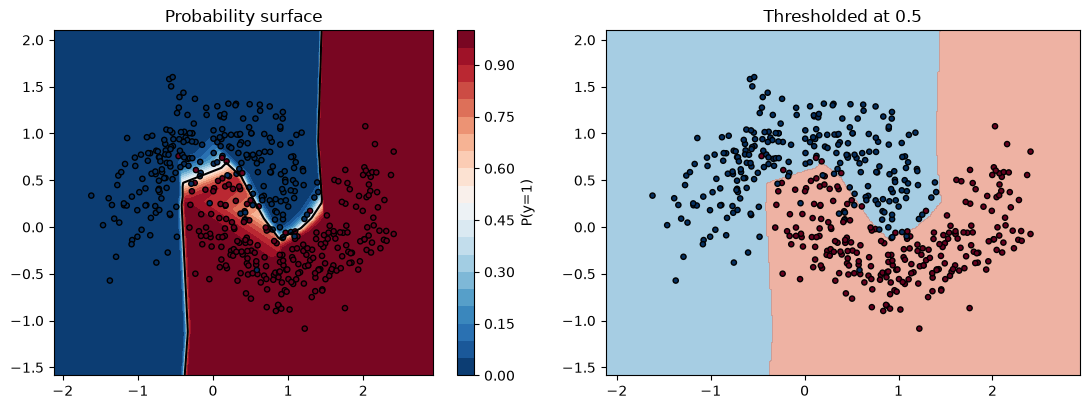

Grid fraction with 0.2 < p < 0.8: 0.029
Grid fraction with p < 0.05 or p > 0.95: 0.93


In [15]:
pad = 0.5
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
    np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300),
)
grid = np.c_[xx.ravel(), yy.ravel()]
prob_grid = final_model.predict_proba(grid)[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
c = ax[0].contourf(xx, yy, prob_grid, levels=np.linspace(0, 1, 21), cmap='RdBu_r')
ax[0].contour(xx, yy, prob_grid, levels=[0.5], colors='k', linewidths=1.5)
ax[0].scatter(X_trainval[:, 0], X_trainval[:, 1], c=y_trainval, cmap='RdBu_r', edgecolor='k', s=14)
fig.colorbar(c, ax=ax[0], label='P(y=1)')
ax[0].set_title('Probability surface')
ax[1].contourf(xx, yy, (prob_grid >= 0.5).astype(int), levels=[-.5, .5, 1.5], cmap='RdBu_r', alpha=.6)
ax[1].scatter(X_trainval[:, 0], X_trainval[:, 1], c=y_trainval, cmap='RdBu_r', edgecolor='k', s=14)
ax[1].set_title('Thresholded at 0.5')
plt.tight_layout(); plt.show()

print('Grid fraction with 0.2 < p < 0.8:', ((prob_grid > .2) & (prob_grid < .8)).mean().round(3))
print('Grid fraction with p < 0.05 or p > 0.95:', ((prob_grid < .05) | (prob_grid > .95)).mean().round(3))

Thresholding at 0.5 hides how confident the model is. In the thresholded panel the final ReLU model looks like a clean boundary with two classes on either side, but the probability surface shows that 93% of the grid has p < 0.05 or p > 0.95, and only 2.9% lies in 0.2 < p < 0.8. The transition between classes is a very thin band, even though the moons overlap and the real class probabilities near the boundary should be less certain.

The surface also shows saturated probabilities in regions with no training points (far left, far right and bottom), where the model extrapolates with straight, near-vertical boundaries. The thresholded plot colours these regions as confidently as the well-supported ones, so it hides that the predictions there are not backed by data.